In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

file_path = "../data/retail_sales_dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (12000, 19)


,order_id,order_date,customer_id,customer_age,gender,region,product_category,product_name,unit_price,quantity,discount_pct,order_channel,payment_method,shipping_cost,delivery_days,returned,customer_rating,total_amount,profit
0,ORD100000,2024-01-01,C3132,30.0,Male,North America,Electronics,Tablet,527.25,1,5,Website,UPI/Wallet,0.00,3,No,4.0,500.89,89.64
1,ORD100001,2024-01-01,C2847,32.0,Male,Europe,Sports,Fitness Band,163.07,2,0,Website,Credit Card,0.00,6,No,5.0,326.14,136.98
2,ORD100002,2024-01-01,C2756,48.0,Male,Oceania,Sports,Fitness Band,153.95,1,0,Website,Credit Card,0.00,7,No,5.0,153.95,64.66
3,ORD100003,2024-01-01,C2766,53.0,Male,North America,Books,Novel,8.78,1,0,Physical Store,Credit Card,0.00,0,No,5.0,8.78,3.34
4,ORD100004,2024-01-01,C1636,34.0,Male,Europe,Toys,Building Blocks,17.11,1,0,Mobile App,Credit Card,5.14,6,No,2.0,22.25,7.70


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Data Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (12000, 19)

Column Data Types:
order_id                str
order_date              str
customer_id             str
customer_age        float64
gender                  str
region                  str
product_category        str
product_name            str
unit_price          float64
quantity              int64
discount_pct          int64
order_channel           str
payment_method          str
shipping_cost       float64
delivery_days         int64
returned                str
customer_rating     float64
total_amount        float64
profit              float64
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          12000 non-null  str    
 1   order_date        12000 non-null  str    
 2   customer_id       12000 non-null  str    
 3   customer_age      11836 non-null  float64
 4   

order_id               0
order_date             0
customer_id            0
customer_age         164
gender                 0
region                 0
product_category       0
product_name           0
unit_price             0
quantity               0
discount_pct           0
order_channel          0
payment_method         0
shipping_cost          0
delivery_days          0
returned               0
customer_rating     2185
total_amount           0
profit                 0
dtype: int64


Duplicate Rows: 0


In [5]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Order IDs:", df["order_id"].duplicated().sum())

print("\nMissing Values Summary:")

missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

display(missing[missing["Missing Values"] > 0])

Duplicate Rows: 0
Duplicate Order IDs: 0

Missing Values Summary:


,Missing Values,Percentage
customer_age,164,1.37
customer_rating,2185,18.21


In [6]:
df["order_date"] = pd.to_datetime(df["order_date"])

customer_check = df.groupby("customer_id").agg(
    Different_Ages=("customer_age", "nunique"),
    Different_Genders=("gender", "nunique")
)

print("Date Range:")
print(df["order_date"].min(), "to", df["order_date"].max())

print("\nUnique Customers:", df["customer_id"].nunique())

print("\nCustomers with Different Ages:",
      (customer_check["Different_Ages"] > 1).sum())

print("Customers with Different Genders:",
      (customer_check["Different_Genders"] > 1).sum())

Date Range:
2024-01-01 00:00:00 to 2025-12-31 00:00:00

Unique Customers: 2130

Customers with Different Ages: 0
Customers with Different Genders: 0


In [7]:
age_mapping = df.groupby("customer_id")["customer_age"].first()

df["customer_age"] = df["customer_age"].fillna(
    df["customer_id"].map(age_mapping)
)

print("Missing Customer Ages After Cleaning:",
      df["customer_age"].isnull().sum())

print("Missing Customer Ratings:",
      df["customer_rating"].isnull().sum())

Missing Customer Ages After Cleaning: 7
Missing Customer Ratings: 2185


In [8]:
product_check = df.groupby("product_name").agg(
    Different_Categories=("product_category", "nunique"),
    Different_Prices=("unit_price", "nunique"),
    Min_Price=("unit_price", "min"),
    Max_Price=("unit_price", "max")
)

print("Unique Products:", df["product_name"].nunique())

print("Unique Categories:", df["product_category"].nunique())

print("\nProducts with Multiple Categories:",
      (product_check["Different_Categories"] > 1).sum())

print("Products with Different Prices:",
      (product_check["Different_Prices"] > 1).sum())

print("\nProduct Price Details:")
display(product_check.head(10))

Unique Products: 42
Unique Categories: 7

Products with Multiple Categories: 0
Products with Different Prices: 42

Product Price Details:


,Different_Categories,Different_Prices,Min_Price,Max_Price
product_name,,,,
Air Fryer,1,259,32.03,43.31
Art Kit,1,205,68.02,91.95
Bedsheet Set,1,301,85.08,114.95
Biography,1,178,38.35,51.73
Blender,1,271,56.62,76.35
Bluetooth Speaker,1,414,219.82,297.06
Board Game,1,182,21.47,29.02
Building Blocks,1,171,12.78,17.26
Coffee Maker,1,272,116.82,157.76


In [9]:
print("Invalid Customer Ages:",
      ((df["customer_age"] < 18) | (df["customer_age"] > 100)).sum())

print("Invalid Unit Prices:",
      (df["unit_price"] <= 0).sum())

print("Invalid Quantities:",
      (df["quantity"] <= 0).sum())

print("Invalid Discounts:",
      ((df["discount_pct"] < 0) | (df["discount_pct"] > 100)).sum())

print("Invalid Shipping Costs:",
      (df["shipping_cost"] < 0).sum())

expected_total = (
    df["unit_price"] * df["quantity"] *
    (1 - df["discount_pct"] / 100)
    + df["shipping_cost"]
).round(2)

differences = (df["total_amount"] - expected_total).abs()

print("\nIncorrect Total Amounts:", (differences > 0.01).sum())

Invalid Customer Ages: 0
Invalid Unit Prices: 0
Invalid Quantities: 0
Invalid Discounts: 0
Invalid Shipping Costs: 0

Incorrect Total Amounts: 16


In [10]:
incorrect_orders = df.loc[
    differences > 0.01,
    [
        "order_id",
        "unit_price",
        "quantity",
        "discount_pct",
        "shipping_cost",
        "total_amount"
    ]
].copy()

incorrect_orders["expected_total"] = expected_total[
    differences > 0.01
]

incorrect_orders["difference"] = (
    incorrect_orders["total_amount"] -
    incorrect_orders["expected_total"]
)

display(incorrect_orders)

,order_id,unit_price,quantity,discount_pct,shipping_cost,total_amount,expected_total,difference
919,ORD100919,22.30,1,5,7.29,28.47,28.48,-0.01
1742,ORD101742,44.25,1,10,4.80,44.63,44.62,0.01
4888,ORD104888,64.25,1,10,5.34,63.16,63.17,-0.01
5820,ORD105820,26.10,1,5,8.65,33.45,33.44,0.01
6048,ORD106048,46.75,1,10,4.37,46.45,46.44,0.01
6660,ORD106660,29.05,1,10,3.97,30.11,30.12,-0.01
6814,ORD106814,73.50,1,5,5.53,75.35,75.36,-0.01
7025,ORD107025,15.31,5,10,5.83,74.73,74.72,0.01
7202,ORD107202,46.50,1,5,9.41,53.59,53.58,0.01
7624,ORD107624,40.65,2,15,7.93,77.03,77.04,-0.01


In [11]:
expected_total_alt = (
    (df["unit_price"] * df["quantity"] *
     (1 - df["discount_pct"] / 100)).round(2)
    + df["shipping_cost"]
).round(2)

differences_alt = (
    df["total_amount"] - expected_total_alt
).abs()

print(
    "Incorrect Records with Alternative Formula:",
    (differences_alt > 0.01).sum()
)

print(
    "Maximum Difference:",
    differences_alt.max()
)

Incorrect Records with Alternative Formula: 0
Maximum Difference: 0.0


In [12]:
categorical_columns = [
    "gender",
    "region",
    "product_category",
    "order_channel",
    "payment_method",
    "returned"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


gender:
gender
Female    6021
Male      5487
Other      492
Name: count, dtype: int64

region:
region
North America    3616
Europe           3146
Asia             2890
Oceania           994
South America     786
Africa            568
Name: count, dtype: int64

product_category:
product_category
Electronics       2561
Clothing          2341
Home & Kitchen    1771
Beauty            1516
Sports            1445
Toys              1245
Books             1121
Name: count, dtype: int64

order_channel:
order_channel
Mobile App        4942
Website           4694
Physical Store    2364
Name: count, dtype: int64

payment_method:
payment_method
Credit Card         4316
Debit Card          2983
UPI/Wallet          2237
Cash on Delivery    1943
Gift Card            521
Name: count, dtype: int64

returned:
returned
No     10996
Yes     1004
Name: count, dtype: int64


In [13]:
for column in categorical_columns:
    print(f"\n{'=' * 40}")
    print(f"{column} ({df[column].nunique()} unique values)")
    print(sorted(df[column].dropna().unique()))


gender (3 unique values)
['Female', 'Male', 'Other']

region (6 unique values)
['Africa', 'Asia', 'Europe', 'North America', 'Oceania', 'South America']

product_category (7 unique values)
['Beauty', 'Books', 'Clothing', 'Electronics', 'Home & Kitchen', 'Sports', 'Toys']

order_channel (3 unique values)
['Mobile App', 'Physical Store', 'Website']

payment_method (5 unique values)
['Cash on Delivery', 'Credit Card', 'Debit Card', 'Gift Card', 'UPI/Wallet']

returned (2 unique values)
['No', 'Yes']


In [14]:
numeric_columns = df.select_dtypes(include="number").columns

display(df[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
customer_age,11993.0,35.752272,11.227865,18.00,27.0000,35.000,44.00,72.00
unit_price,12000.0,127.379702,140.732538,8.33,40.3450,76.310,148.29,689.81
quantity,12000.0,1.607167,0.970272,1.00,1.0000,1.000,2.00,5.00
discount_pct,12000.0,4.936667,6.737626,0.00,0.0000,0.000,10.00,30.00
shipping_cost,12000.0,1.742078,2.934061,0.00,0.0000,0.000,3.46,9.49
delivery_days,12000.0,4.002167,2.596130,0.00,2.0000,4.000,6.00,14.00
customer_rating,9815.0,4.185736,0.768654,1.00,4.0000,4.000,5.00,5.00
total_amount,12000.0,165.316997,159.834327,6.70,57.6275,111.825,213.27,1372.92
profit,12000.0,51.180718,43.532571,-54.09,19.4000,39.020,70.69,357.77


In [15]:
print("Negative Profit Records:",
      (df["profit"] < 0).sum())

print("\nNegative Profit by Return Status:")
display(
    df.groupby("returned")["profit"]
    .agg(["count", "mean", "min", "max"])
)

print("\nCustomer Rating Distribution:")
print(df["customer_rating"].value_counts().sort_index())

print("\nZero Delivery Days:",
      (df["delivery_days"] == 0).sum())

Negative Profit Records: 44

Negative Profit by Return Status:


,count,mean,min,max
returned,,,,
No,10996,50.614159,-54.09,347.80
Yes,1004,57.385777,-42.08,357.77



Customer Rating Distribution:
customer_rating
1.0      11
2.0     226
3.0    1413
4.0    4444
5.0    3721
Name: count, dtype: int64

Zero Delivery Days: 2364


In [16]:
same_day_orders = df[df["delivery_days"] == 0]

print("Same-day Orders:", len(same_day_orders))

print("\nBy Order Channel:")
display(same_day_orders["order_channel"].value_counts())

print("\nBy Region:")
display(same_day_orders["region"].value_counts())

print("\nReturned Status:")
display(same_day_orders["returned"].value_counts())

Same-day Orders: 2364

By Order Channel:


order_channel
Physical Store    2364
Name: count, dtype: int64


By Region:


region
North America    709
Europe           597
Asia             565
Oceania          219
South America    161
Africa           113
Name: count, dtype: int64


Returned Status:


returned
No     2238
Yes     126
Name: count, dtype: int64

In [17]:
df["year"] = df["order_date"].dt.year

df["month"] = df["order_date"].dt.month

df["month_name"] = df["order_date"].dt.strftime("%b")

df["quarter"] = df["order_date"].dt.to_period("Q")

df["age_group"] = pd.cut(
    df["customer_age"],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "65+"
    ]
)

display(df[
    ["order_date", "year", "month", "month_name",
     "quarter", "customer_age", "age_group"]
].head(10))

,order_date,year,month,month_name,quarter,customer_age,age_group
0,2024-01-01,2024,1,Jan,2024Q1,30.0,26-35
1,2024-01-01,2024,1,Jan,2024Q1,32.0,26-35
2,2024-01-01,2024,1,Jan,2024Q1,48.0,46-55
3,2024-01-01,2024,1,Jan,2024Q1,53.0,46-55
4,2024-01-01,2024,1,Jan,2024Q1,34.0,26-35
5,2024-01-01,2024,1,Jan,2024Q1,53.0,46-55
6,2024-01-01,2024,1,Jan,2024Q1,30.0,26-35
7,2024-01-01,2024,1,Jan,2024Q1,18.0,18-25
8,2024-01-01,2024,1,Jan,2024Q1,54.0,46-55
9,2024-01-01,2024,1,Jan,2024Q1,30.0,26-35


In [18]:
numeric_columns = df.select_dtypes(include="number").columns

descriptive_stats = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Mode": df[numeric_columns].mode().iloc[0],
    "Standard Deviation": df[numeric_columns].std()
})

display(descriptive_stats.round(2))

,Mean,Median,Mode,Standard Deviation
customer_age,35.75,35.00,18.00,11.23
unit_price,127.38,76.31,25.55,140.73
quantity,1.61,1.00,1.00,0.97
discount_pct,4.94,0.00,0.00,6.74
shipping_cost,1.74,0.00,0.00,2.93
delivery_days,4.00,4.00,0.00,2.60
customer_rating,4.19,4.00,4.00,0.77
total_amount,165.32,111.82,63.27,159.83
profit,51.18,39.02,11.56,43.53
year,2024.54,2025.00,2025.00,0.50


In [19]:

from pathlib import Path

OUTPUT_DIR = Path(
    r"D:\OasisInfobyte\OIBSIP\Task1_Retail_Sales_EDA\outputs"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder is ready:", OUTPUT_DIR)


Output folder is ready: D:\OasisInfobyte\OIBSIP\Task1_Retail_Sales_EDA\outputs


,order_date,Total_Sales,Total_Orders
0,2024-01-01,53836.93,346
1,2024-02-01,61741.46,383
2,2024-03-01,70664.80,405
3,2024-04-01,63923.65,403
4,2024-05-01,73521.78,431


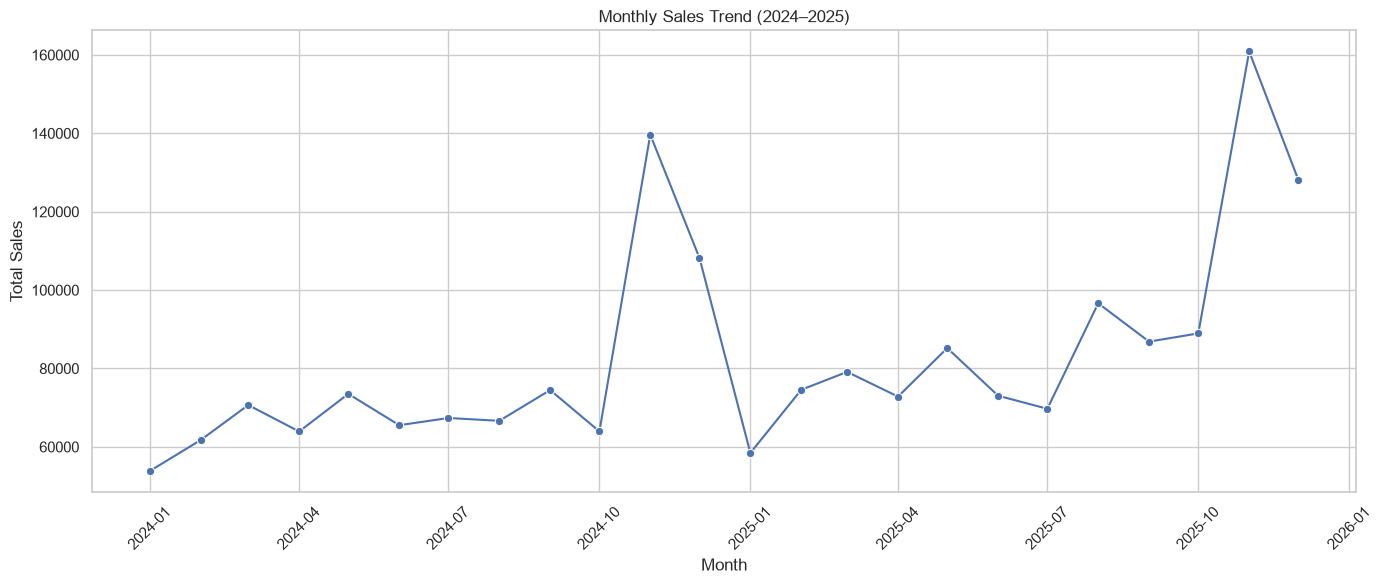

In [20]:

monthly_sales = (
    df.groupby(df["order_date"].dt.to_period("M"))
    .agg(
        Total_Sales=("total_amount", "sum"),
        Total_Orders=("order_id", "nunique")
    )
    .reset_index()
)

monthly_sales["order_date"] = (
    monthly_sales["order_date"].dt.to_timestamp()
)

display(monthly_sales.head())

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="order_date",
    y="Total_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [23]:

highest_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmax()
]

lowest_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmin()
]

print("Highest Sales Month:")
display(highest_month)

print("Lowest Sales Month:")
display(lowest_month)


Highest Sales Month:


order_date      2025-11-01 00:00:00
Total_Sales               160889.16
Total_Orders                    981
Name: 22, dtype: object

Lowest Sales Month:


order_date      2024-01-01 00:00:00
Total_Sales                53836.93
Total_Orders                    346
Name: 0, dtype: object

In [24]:
print("Highest Sales Month:")
display(highest_month)

print("Lowest Sales Month:")
display(lowest_month)

Highest Sales Month:


order_date      2025-11-01 00:00:00
Total_Sales               160889.16
Total_Orders                    981
Name: 22, dtype: object

Lowest Sales Month:


order_date      2024-01-01 00:00:00
Total_Sales                53836.93
Total_Orders                    346
Name: 0, dtype: object

**Observation:**

Monthly sales showed noticeable fluctuations throughout the two-year period. November 2025 recorded the highest sales, reaching 160,889.16 across 981 orders, while January 2024 recorded the lowest sales at 53,836.93 across 346 orders. Overall, sales varied considerably over time, with a notable peak toward the end of 2025.

,quarter,Total_Sales,Total_Orders
0,2024Q1,186243.19,1134
1,2024Q2,202971.10,1215
2,2024Q3,208498.17,1196
3,2024Q4,311760.72,1949
4,2025Q1,212128.00,1300
5,2025Q2,231074.02,1392
6,2025Q3,253208.12,1483
7,2025Q4,377920.64,2331


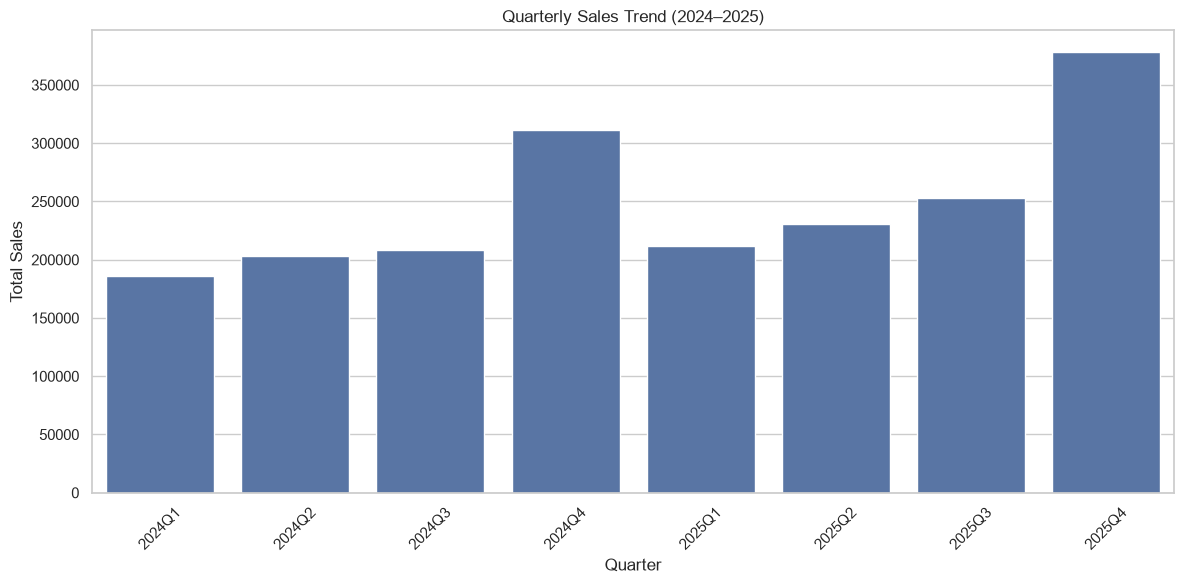

In [25]:

quarterly_sales = (
    df.groupby("quarter")
    .agg(
        Total_Sales=("total_amount", "sum"),
        Total_Orders=("order_id", "nunique")
    )
    .reset_index()
)

quarterly_sales["quarter"] = quarterly_sales["quarter"].astype(str)

display(quarterly_sales)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=quarterly_sales,
    x="quarter",
    y="Total_Sales"
)

plt.title("Quarterly Sales Trend (2024–2025)")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "quarterly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Observation

Quarterly sales showed an overall upward trend across the two years. The fourth quarter recorded the highest sales in both years, reaching 311,760.72 in Q4 2024 and 377,920.64 in Q4 2025. Q1 2024 had the lowest sales at 186,243.19. This pattern suggests a possible seasonal increase in sales toward the end of the year.

In [ ]:
yearly_sales = (
    df.groupby("year")
    .agg(
        Total_Sales=("total_amount", "sum"),
        Total_Orders=("order_id", "nunique")
    )
)

yearly_sales["Sales_Growth_%"] = (
    yearly_sales["Total_Sales"].pct_change() * 100
)

display(yearly_sales.round(2))

,Total_Sales,Total_Orders,Sales_Growth_%
year,,,
2024,909473.18,5494,NaN
2025,1074330.78,6506,18.13


### Observation

Annual sales increased from 909,473.18 in 2024 to 1,074,330.78 in 2025, representing an 18.13% growth. The total number of orders also increased from 5,494 to 6,506, indicating that the sales growth was mainly associated with a higher order volume.

,age_group,Total_Orders,Total_Sales,Average_Sales
0,18-25,2549,442857.16,173.74
1,26-35,3548,584135.10,164.64
2,36-45,3524,573436.15,162.72
3,46-55,1790,289970.29,161.99
4,56-65,494,81197.52,164.37
5,65+,88,11532.70,131.05


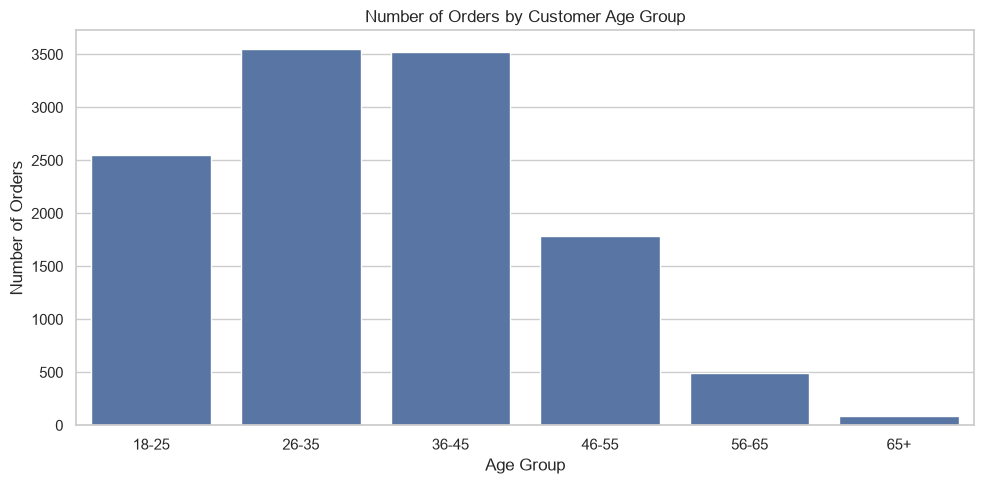

In [26]:

age_analysis = (
    df.groupby("age_group", observed=False)
    .agg(
        Total_Orders=("order_id", "nunique"),
        Total_Sales=("total_amount", "sum"),
        Average_Sales=("total_amount", "mean")
    )
    .reset_index()
)

display(age_analysis.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_analysis,
    x="age_group",
    y="Total_Orders"
)

plt.title("Number of Orders by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Orders")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "customer_age_groups.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Observation

Customers aged 26–35 generated the highest number of orders (3,548) and the highest total sales (584,135.10), closely followed by the 36–45 age group. However, customers aged 18–25 had the highest average order value at 173.74. The 65+ group recorded the lowest order volume and average sales.

,gender,Total_Orders,Total_Sales,Average_Sales
0,Female,6021,900779.96,149.61
1,Male,5487,1002225.44,182.65
2,Other,492,80798.56,164.22


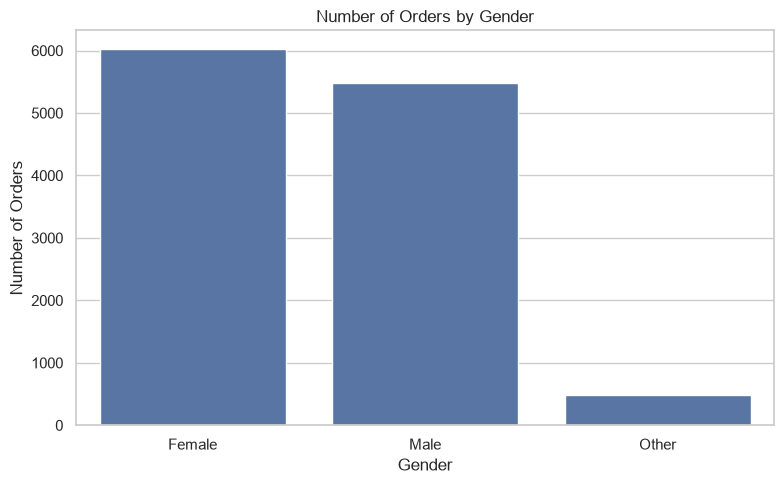

In [27]:

gender_analysis = (
    df.groupby("gender")
    .agg(
        Total_Orders=("order_id", "nunique"),
        Total_Sales=("total_amount", "sum"),
        Average_Sales=("total_amount", "mean")
    )
    .reset_index()
)

display(gender_analysis.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_analysis,
    x="gender",
    y="Total_Orders"
)

plt.title("Number of Orders by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Orders")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "orders_by_gender.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


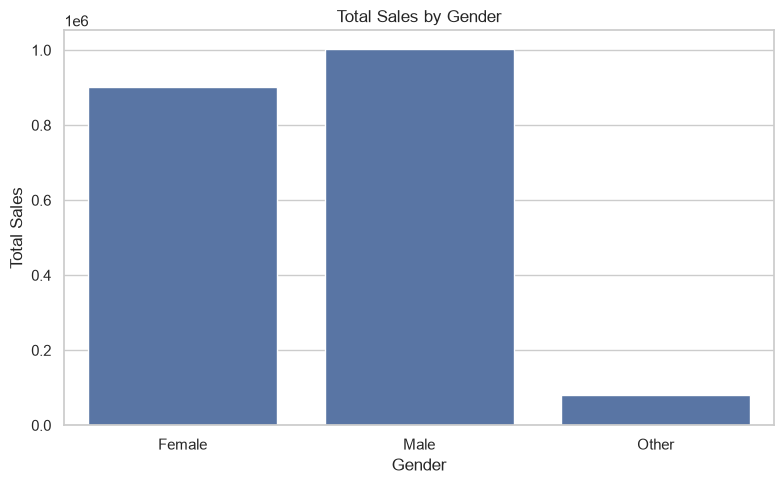

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(data=gender_analysis, x="gender", y="Total_Sales")

plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

### Observation

Female customers generated the highest number of orders (6,021), while male customers achieved the highest total sales (1,002,225.44) despite placing fewer orders. Male customers also recorded the highest average sales per order at 182.65, compared to 149.61 for female customers. This indicates differences in average order value across customer groups.

,product_name,Total_Quantity,Total_Orders,Total_Revenue
0,Wireless Earbuds,767,430,59442.49
1,Jeans,736,424,32720.44
2,Hoodie,687,387,44214.01
3,Dress,665,427,87400.95
4,Jacket,658,371,70651.80
5,T-Shirt,646,373,18206.43
6,Running Shoes,633,359,53754.77
7,Bedsheet Set,549,316,52787.62
8,Smart Watch,543,417,82073.90
9,Air Fryer,543,301,20612.00


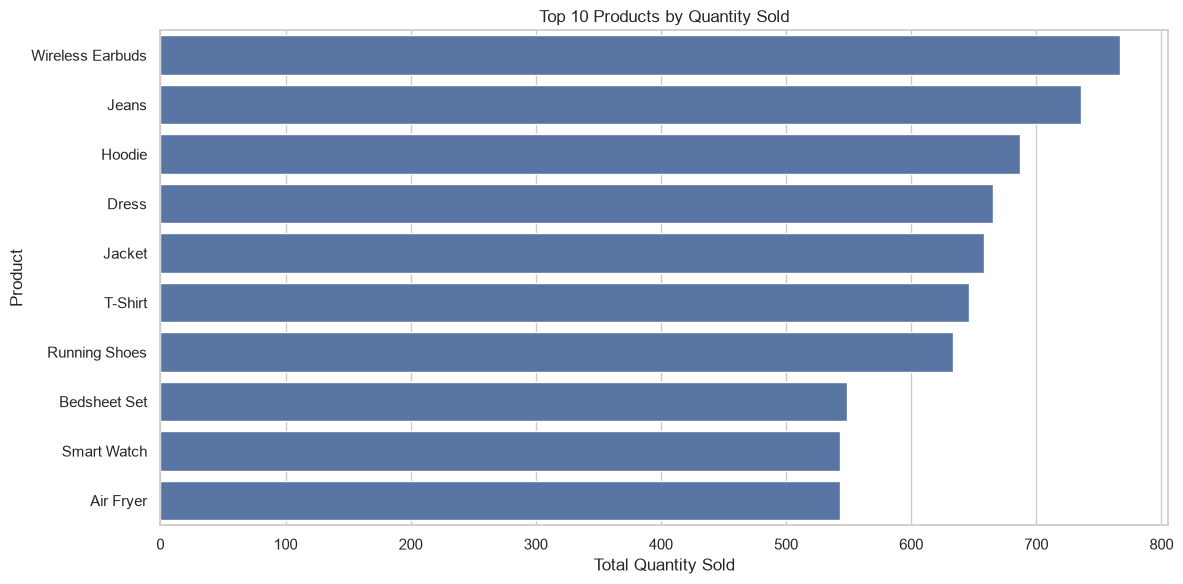

In [28]:

top_products = (
    df.groupby("product_name")
    .agg(
        Total_Quantity=("quantity", "sum"),
        Total_Orders=("order_id", "nunique"),
        Total_Revenue=("total_amount", "sum")
    )
    .sort_values("Total_Quantity", ascending=False)
    .head(10)
    .reset_index()
)

display(top_products.round(2))

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="Total_Quantity",
    y="product_name"
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "top_10_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Observation

Wireless Earbuds ranked first among the top 10 best-selling products, with 767 units sold, followed by Jeans with 736 units. However, Dress generated the highest total revenue among these products, reaching 87,400.95, despite ranking fourth in sales quantity. This highlights the difference between product sales volume and revenue contribution.

,product_category,Total_Quantity,Total_Orders,Total_Revenue,Revenue_Percentage
0,Electronics,3184,2561,900076.54,45.37
1,Clothing,4025,2341,306948.40,15.47
2,Home & Kitchen,2742,1771,290420.16,14.64
3,Sports,2376,1445,196519.04,9.91
4,Beauty,2728,1516,134771.17,6.79
5,Toys,2226,1245,101165.47,5.10
6,Books,2005,1121,53903.18,2.72


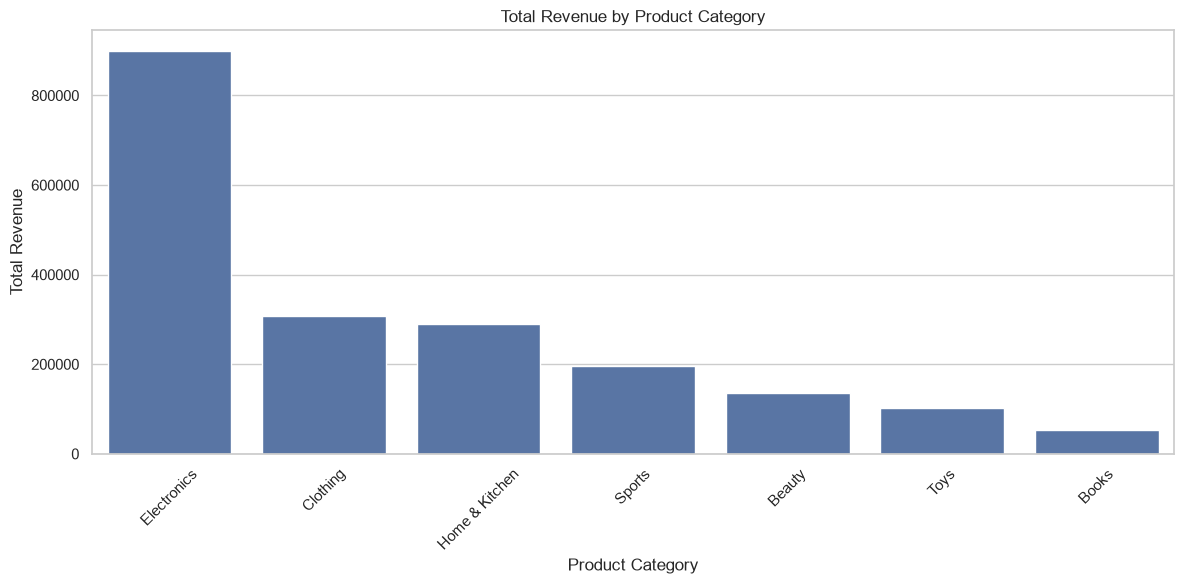

In [29]:

category_sales = (
    df.groupby("product_category")
    .agg(
        Total_Quantity=("quantity", "sum"),
        Total_Orders=("order_id", "nunique"),
        Total_Revenue=("total_amount", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
    .reset_index()
)

category_sales["Revenue_Percentage"] = (
    category_sales["Total_Revenue"] /
    category_sales["Total_Revenue"].sum() * 100
)

display(category_sales.round(2))

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_sales,
    x="product_category",
    y="Total_Revenue"
)

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "revenue_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Observation

Electronics generated the highest revenue, reaching 900,076.54 and contributing 45.37% of total revenue, despite selling fewer units than Clothing. Clothing recorded the highest sales volume with 4,025 units but generated 306,948.40 in revenue. Books had the lowest revenue contribution at 2.72%. These results highlight the significant differences in revenue contribution across product categories.

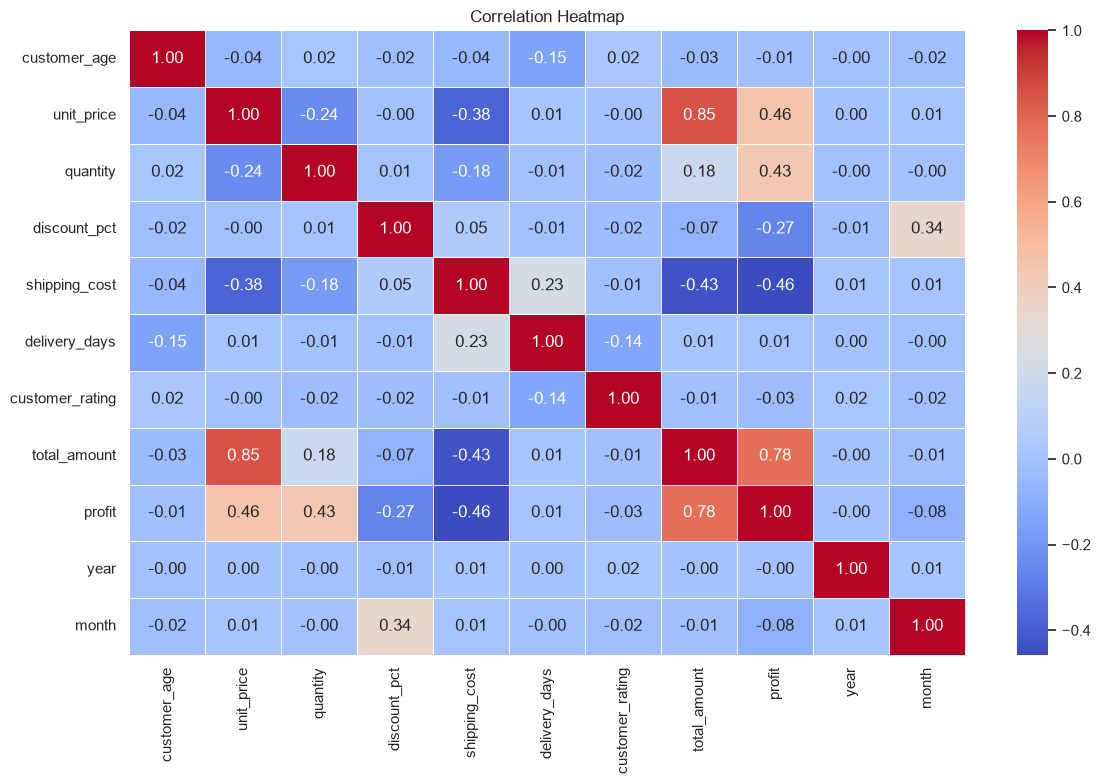

In [30]:

correlation_matrix = df.select_dtypes(include="number").corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
correlation_matrix = df.select_dtypes(include="number").corr()

correlations = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

correlations.columns = ["Variable 1", "Variable 2", "Correlation"]

correlations["Absolute Correlation"] = (
    correlations["Correlation"].abs()
)

display(
    correlations
    .sort_values("Absolute Correlation", ascending=False)
    .round(3)
    .head(15)
)

,Variable 1,Variable 2,Correlation,Absolute Correlation
18,unit_price,total_amount,0.847,0.847
85,total_amount,profit,0.776,0.776
52,shipping_cost,profit,-0.457,0.457
19,unit_price,profit,0.456,0.456
30,quantity,profit,0.434,0.434
51,shipping_cost,total_amount,-0.432,0.432
15,unit_price,shipping_cost,-0.376,0.376
43,discount_pct,month,0.339,0.339
41,discount_pct,profit,-0.267,0.267
13,unit_price,quantity,-0.239,0.239


### Observation

The correlation analysis revealed a strong positive relationship between unit price and total sales (0.847), as well as between total sales and profit (0.776). Shipping cost showed a moderate negative correlation with profit (-0.457), while discounts had a weaker negative correlation (-0.267). These findings suggest that pricing, shipping expenses, and discount strategies are important factors to consider when evaluating sales and profitability.

In [34]:

channel_analysis = (
    df.groupby("order_channel")
    .agg(
        Total_Orders=("order_id", "nunique"),
        Total_Sales=("total_amount", "sum"),
        Total_Profit=("profit", "sum"),
        Average_Profit=("profit", "mean")
    )
    .reset_index()
)

display(channel_analysis.round(2))


,order_channel,Total_Orders,Total_Sales,Total_Profit,Average_Profit
0,Mobile App,4942,827566.13,254053.01,51.41
1,Physical Store,2364,371703.19,118221.68,50.01
2,Website,4694,784534.64,241893.92,51.53


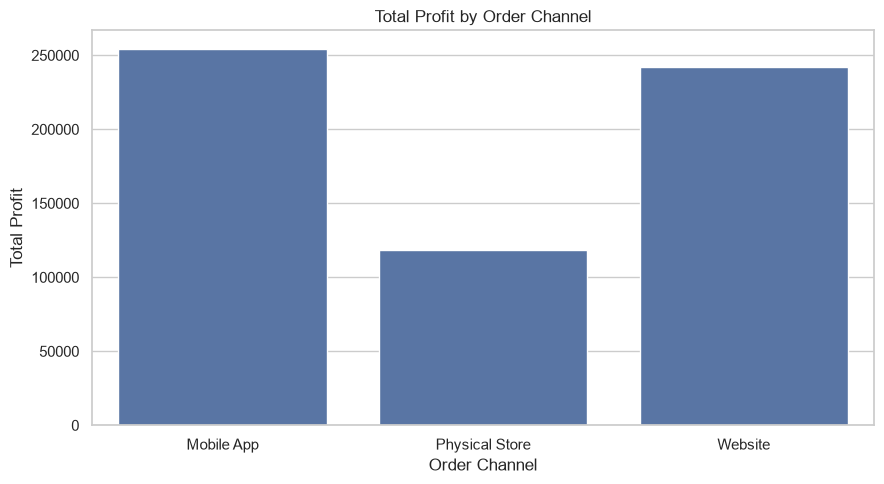

In [35]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=channel_analysis,
    x="order_channel",
    y="Total_Profit"
)

plt.title("Total Profit by Order Channel")
plt.xlabel("Order Channel")
plt.ylabel("Total Profit")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "profit_by_order_channel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


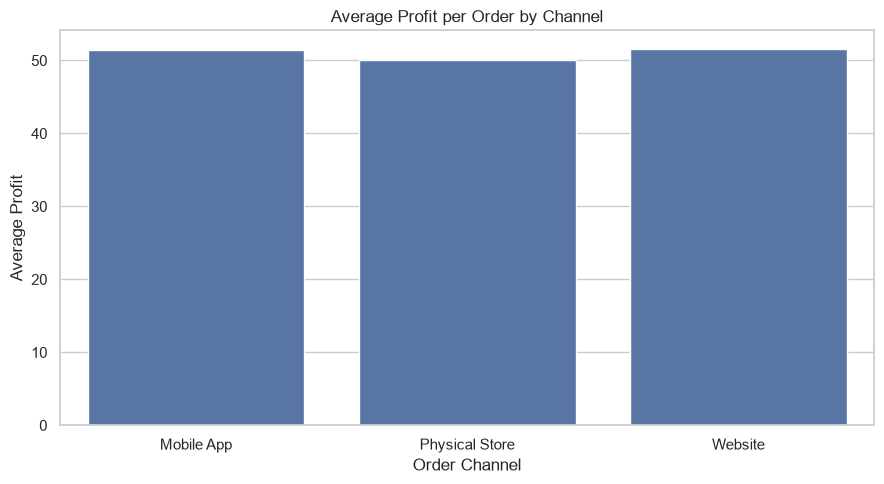

In [36]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=channel_analysis,
    x="order_channel",
    y="Average_Profit"
)

plt.title("Average Profit per Order by Channel")
plt.xlabel("Order Channel")
plt.ylabel("Average Profit")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "average_profit_by_channel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Observation

The Mobile App generated the highest total profit of 254,053.01, supported by the largest number of orders (4,942). The Website followed with a total profit of 241,893.92, while Physical Stores recorded the lowest total profit. However, the average profit per order was very similar across all three channels, ranging from 50.01 to 51.53. This suggests that the Mobile App's higher overall profitability is mainly associated with its greater order volume rather than a significantly higher profit per order.

In [ ]:
profit_by_category = (
    df.groupby("product_category")
    .agg(
        Total_Sales=("total_amount", "sum"),
        Total_Profit=("profit", "sum")
    )
    .reset_index()
)

profit_by_category["Profit_Margin_%"] = (
    profit_by_category["Total_Profit"] /
    profit_by_category["Total_Sales"] * 100
)

profit_by_category = profit_by_category.sort_values(
    "Profit_Margin_%",
    ascending=False
)

display(profit_by_category.round(2))

,product_category,Total_Sales,Total_Profit,Profit_Margin_%
0,Beauty,134771.17,68456.08,50.79
2,Clothing,306948.40,143888.46,46.88
6,Toys,101165.47,41035.85,40.56
5,Sports,196519.04,75576.24,38.46
4,Home & Kitchen,290420.16,106574.62,36.70
1,Books,53903.18,17215.16,31.94
3,Electronics,900076.54,161422.20,17.93


### Observation

Beauty recorded the highest profit margin at 50.79%, followed by Clothing at 46.88%. Although Electronics generated the highest total sales (900,076.54), it had the lowest profit margin at 17.93%. This indicates that high revenue does not necessarily translate into high profitability, highlighting the importance of evaluating both sales performance and profit margins when making business decisions.


## Key Findings

1. **Sales Growth:** Total sales increased by 18.13% in 2025 compared to 2024.

2. **Customer Demographics:** Customers aged 26–35 generated the highest number of orders, while the 18–25 age group had the highest average order value.

3. **Product Performance:** Wireless Earbuds recorded the highest sales quantity among the top 10 products.

4. **Category Performance:** Electronics generated the highest revenue, contributing 45.37% of total sales.

5. **Sales Channels:** The Mobile App recorded the highest number of orders and total profit.

6. **Profitability:** Beauty achieved the highest profit margin (50.79%), while Electronics had the lowest (17.93%).


## Business Recommendations

1. **Optimize Electronics Profitability:** Electronics contributed 45.37% of total sales but had the lowest profit margin (17.93%). Review supplier costs, pricing strategies, and discount levels to improve profitability without reducing sales volume.

2. **Invest in High-Margin Categories:** Beauty and Clothing achieved the highest profit margins at 50.79% and 46.88%, respectively. Consider expanding their promotional campaigns and maintaining sufficient inventory to capitalize on their profitability.

3. **Strengthen the Mobile App Channel:** The Mobile App generated the highest order volume (4,942 orders) and total profit (254,053.01). Improve the app's user experience and targeted marketing campaigns to maintain customer engagement and support further growth.